In [1]:
%pip install "numpy<2"
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import r2_score
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

In [3]:
pd.set_option('display.max_rows',None)
pd.set_option('display.max_columns',None)

In [5]:
df = pd.read_excel('ML_fill.xlsx')

In [6]:
x = df.iloc[:,1:-2]
y = df.iloc[:,-2:]

In [7]:
x1 = x.to_numpy()
x1

array([[13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       ...,
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057]])

In [8]:
y1 = y.to_numpy()
y1

array([[2.07178511, 0.45393188],
       [2.20346309, 0.95345185],
       [2.58669883, 0.31243581],
       [2.40113761, 0.37797118],
       [2.46104524, 0.60049189],
       [2.76000678, 0.96124147],
       [2.89152935, 1.66750219],
       [2.75650686, 0.46764406],
       [3.12888539, 1.59869944],
       [2.93442502, 0.85533034],
       [2.80633574, 0.92496765],
       [3.05979572, 2.10080304],
       [2.86773029, 2.10885006],
       [2.33276232, 0.2184884 ],
       [3.24669369, 1.98031848],
       [2.21126272, 0.39340482],
       [1.64759635, 1.20208812],
       [2.76802748, 0.79128264],
       [3.38947647, 2.60953282],
       [2.8819038 , 1.64676852],
       [1.74882105, 0.40063994],
       [2.1422312 , 0.17205881],
       [1.14823108, 0.6605956 ],
       [2.29170873, 1.05199705],
       [2.72628024, 0.80772191],
       [2.11290345, 0.14094448],
       [2.90144552, 0.56786874],
       [2.90886246, 0.83960681],
       [4.28894422, 2.39609608],
       [2.30412729, 0.41703624],
       [2.

In [13]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x1, y1, test_size=0.15, random_state=0)

In [15]:
x_train_all = x_train.copy()
y_train_all = y_train.copy()
x_test_all = x_test.copy()
y_test_all = y_test.copy()
print(x_train[1])
for i in range(5):
    x_train[:, [i, i + 5]] = x_train[:, [i + 5, i]]
    x_test[:, [i, i + 5]] = x_test[:, [i + 5, i]]

print(x_train[1])

[13.     1.61  67.5   67.5    3.     1.9    0.     1.5   -3.361  6.146
 -2.475  6.49  25.     1.55  81.    72.     7.     2.3    0.     0.
 -0.666  1.014 -0.687  0.532 26.     1.83  75.    69.     8.     2.3
  0.5    0.    -1.609 -1.195 -2.231 -2.167 27.     1.88  79.    68.5
  9.     2.3    0.5    0.    -0.56  -1.206 -0.351 -1.176 28.     1.92
 83.    70.    10.     2.3    0.     1.     0.212 -2.225  0.375 -2.236
 29.     1.9   87.    68.    11.     2.3    0.     0.    -0.862 -1.896
 -0.525 -1.828 30.     1.65  88.    88.    12.     2.3    0.     0.
 -0.106 -5.304  0.601 -6.057]
[ 1.9    0.     1.5   -3.361  6.146 13.     1.61  67.5   67.5    3.
 -2.475  6.49  25.     1.55  81.    72.     7.     2.3    0.     0.
 -0.666  1.014 -0.687  0.532 26.     1.83  75.    69.     8.     2.3
  0.5    0.    -1.609 -1.195 -2.231 -2.167 27.     1.88  79.    68.5
  9.     2.3    0.5    0.    -0.56  -1.206 -0.351 -1.176 28.     1.92
 83.    70.    10.     2.3    0.     1.     0.212 -2.225  0.375 -2.23

In [17]:
x_train_all = np.concatenate((x_train_all, x_train), axis=0)
y_train_all = np.concatenate((y_train_all, y_train), axis=0)
x_test_all = np.concatenate((x_test_all, x_test), axis=0)
y_test_all = np.concatenate((y_test_all, y_test), axis=0)

In [19]:
for i in range(5):
    x_train[:, [i + 10, i + 15]] = x_train[:, [i + 15, i + 10]]
    x_test[:, [i + 10, i + 15]] = x_test[:, [i + 15, i + 10]]

x_train_all = np.concatenate((x_train_all, x_train), axis=0)
y_train_all = np.concatenate((y_train_all, y_train), axis=0)
x_test_all = np.concatenate((x_test_all, x_test), axis=0)
y_test_all = np.concatenate((y_test_all, y_test), axis=0)

In [21]:
for i in range(5):
    x_train[:, [i, i + 5]] = x_train[:, [i + 5, i]]
    x_test[:, [i, i + 5]] = x_test[:, [i + 5, i]]

x_train_all = np.concatenate((x_train_all, x_train), axis=0)
y_train_all = np.concatenate((y_train_all, y_train), axis=0)
x_test_all = np.concatenate((x_test_all, x_test), axis=0)
y_test_all = np.concatenate((y_test_all, y_test), axis=0)

In [23]:
from sklearn.metrics import mean_absolute_error as mae

In [25]:
!pip install xgboost

In [26]:
import xgboost as xgb
model_xgb = xgb.XGBRegressor(learning_rate=0.25, n_estimators=500)

In [27]:
model_xgb.fit(x_train_all, y_train_all)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.25, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [39]:
y_train_xgb_pred = model_xgb.predict(x_train_all)
y_test_xgb_pred = model_xgb.predict(x_test_all)

In [41]:
x_train_xgb_result = []
x_test_xgb_result = []
y_train_xgb_result = []
y_test_xgb_result = []

In [43]:
for i, j in zip(abs(y_train_all[:,0] - y_train_all[:,1]), abs(y_train_all[:,0] - y_train_all[:,1])):
    x_train_xgb_result.append(max(i, j))
for i, j in zip(abs(y_train_xgb_pred[:,0] - y_train_xgb_pred[:,1]), abs(y_train_xgb_pred[:,0] - y_train_xgb_pred[:,1])):
    y_train_xgb_result.append(max(i, j))
for i, j in zip(abs(y_test_all[:,0] - y_test_all[:,1]), abs(y_test_all[:,0] - y_test_all[:,1])):
    x_test_xgb_result.append(max(i, j))
for i, j in zip(abs(y_test_xgb_pred[:,0] - y_test_xgb_pred[:,1]), abs(y_test_xgb_pred[:,0] - y_test_xgb_pred[:,1])):
    y_test_xgb_result.append(max(i, j))

In [45]:
ytrain_xgb = []
ytest_xgb = []

In [47]:
l = len(y_train_xgb_result) // 4

for i in range(l):
    ytrain_xgb.append((y_train_xgb_result[i] + y_train_xgb_result[i + l] + y_train_xgb_result[i + l * 2] + y_train_xgb_result[i + l * 3]) / 4)

k = len(y_test_xgb_result) // 4

for i in range(k):
    ytest_xgb.append((y_test_xgb_result[i] + y_test_xgb_result[i + k] + y_test_xgb_result[i + k * 2] + y_test_xgb_result[i + k * 3]) / 4)

In [49]:
print("Train_Data_X:")
print(x_train_xgb_result[0:l])
print("-" * 13)
print("Train_Data_Y:")
print(ytrain_xgb)
print("-" * 13)
print("Test_Data_X:")
print(x_test_xgb_result[0:k])
print("-" * 13)
print("Test_Data_Y:")
print(ytest_xgb)

Train_Data_X:
[1.8588518669708192, 1.0381181779013462, 0.7502986017252589, 1.740909637081548, 1.987446541312179, 1.5605585965366011, 1.9185583325941007, 0.10255585994019079, 1.9993530773420758, 1.2351352815717969, 2.2323757469971843, 1.9041785989251128, 0.4455082334069249, 1.903214968999598, 1.4487727005841022, 1.5845732211866523, 0.4876354761293289, 2.1370728893074875, 2.09292812476557, 1.2129370641938528, 1.5314472133819699, 1.880231244692893, 2.0692556457348297, 2.0164933299138226, 1.374446992478143, 1.1272569868622202, 0.33109712745133724, 0.7799436458081677, 0.22278502767891117, 2.2272530944091358, 2.3080858022564437, 1.6865261354139294, 1.8228751219635837, 2.2742630179550085, 2.1554705510578445, 0.5559047968845001, 0.9460386079465408, 2.0865821461483898, 2.234298401193202, 1.8813680958995898, 1.1478097561317693, 1.0653535439757749, 1.4854998225076788, 1.8621896462633827, 1.916924870447801, 1.334480223492501, 1.356875880294207, 2.053436732045857, 2.0082601974032666, 1.407401478655

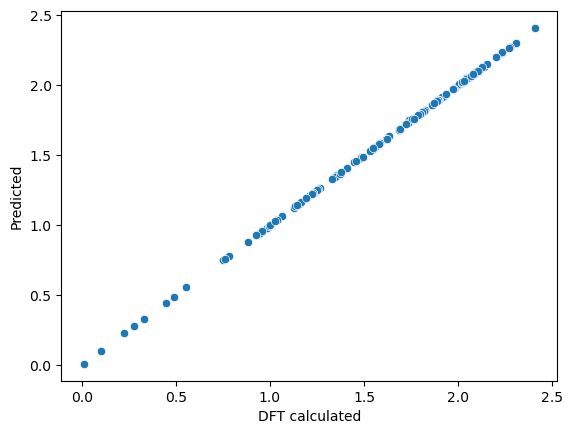

In [51]:
df_xgb_tr = pd.DataFrame({'DFT calculated':x_train_xgb_result[0:l], 'Predicted':ytrain_xgb})
img_xgb = sns.scatterplot(x="DFT calculated", y="Predicted", data=df_xgb_tr).get_figure()

In [53]:
mae_XG_train = mae(x_train_xgb_result[0:l], ytrain_xgb)
print("Train MAE:", mae_XG_train)

Train MAE: 0.0018253653066284065


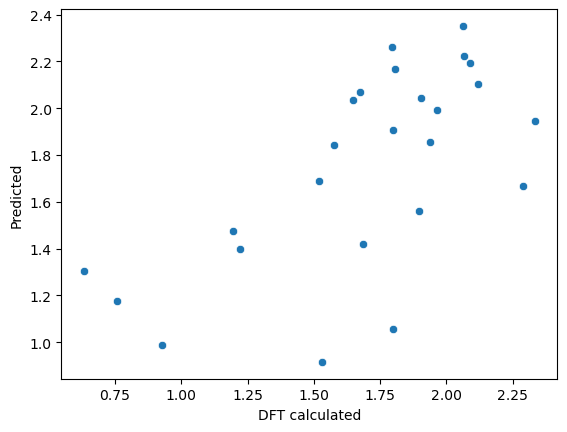

In [55]:
df_xgb_tr2 = pd.DataFrame({'DFT calculated':x_test_xgb_result[0:k], 'Predicted':ytest_xgb})
img2_xgb = sns.scatterplot(x="DFT calculated", y="Predicted", data=df_xgb_tr2).get_figure()

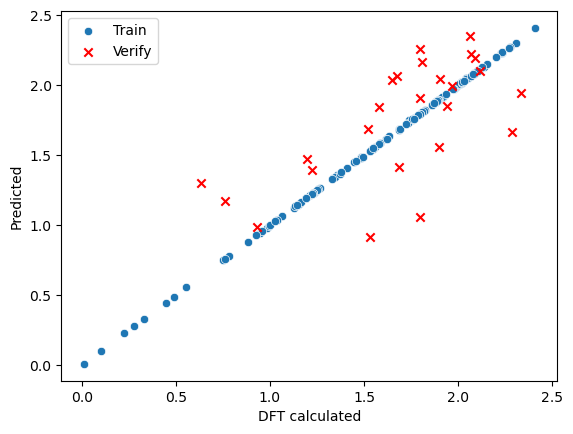

In [57]:
sns.scatterplot(x="DFT calculated", y="Predicted", data=df_xgb_tr, label="Train")

ax = plt.gca()  # 获取当前轴
ax.scatter(df_xgb_tr2["DFT calculated"], df_xgb_tr2["Predicted"], color="red", marker="x", label="Verify")

plt.legend()
plt.show()

In [65]:
df_xgb_pre = pd.read_excel('ML_xgb_predict.xlsx')

In [68]:
x_xgb_pre = df_xgb_pre.iloc[:,1:]
x_xgb_pre = x_xgb_pre.to_numpy()
x_xgb_pre

array([[13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       ...,
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057],
       [13.   ,  1.61 , 67.5  , ..., -5.304,  0.601, -6.057]])

In [70]:
y_xgb_pre = model_xgb.predict(x_xgb_pre)
y_xgb_pre

array([[2.5153248 , 0.6333148 ],
       [2.9346015 , 0.85438585],
       [3.0594554 , 2.0998151 ],
       [2.4607537 , 0.6015502 ],
       [2.1124215 , 0.13993828],
       [3.172639  , 2.2021654 ],
       [1.6469231 , 1.202422  ],
       [2.889536  , 1.6671267 ],
       [2.0721009 , 0.4539005 ],
       [2.1418629 , 0.16954312],
       [1.7491317 , 0.39988825],
       [2.6357214 , 0.9310296 ],
       [1.1486819 , 0.6600472 ],
       [2.2882466 , 1.0555804 ],
       [2.7291281 , 0.8067929 ],
       [3.2473135 , 1.9788471 ],
       [2.0260196 , 0.38591412],
       [2.274016  , 1.0255339 ],
       [1.6819451 , 1.4149109 ],
       [2.6682084 , 1.235872  ],
       [2.5106876 , 0.30288476],
       [3.3595068 , 0.71784645],
       [1.9931204 , 0.7430616 ],
       [2.740661  , 1.1085696 ],
       [1.1605494 , 0.6148173 ],
       [1.3980336 , 0.8339806 ],
       [2.2699292 , 1.3670037 ],
       [2.274016  , 1.0255339 ],
       [1.9486957 , 1.3486809 ],
       [2.6682084 , 1.235872  ],
       [2.

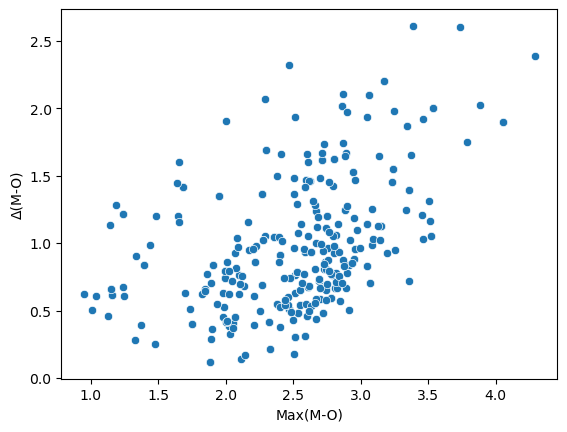

In [72]:
df_xgb_p = pd.DataFrame({'Max(M-O)':y_xgb_pre[:,0], 'Δ(M-O)':y_xgb_pre[:,1]})
img_xgb_p = sns.scatterplot(x="Max(M-O)", y="Δ(M-O)", data=df_xgb_p).get_figure()

In [40]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [41]:
    print('xgb R2: ',r2_score(x_train_xgb_result[0:l], ytrain_xgb))
    print('xgb MAE: ',mean_absolute_error(x_train_xgb_result[0:l], ytrain_xgb))
    print('xgb MSE: ',mean_squared_error(x_train_xgb_result[0:l], ytrain_xgb))

xgb R2:  0.9999712757275547
xgb MAE:  0.0018253653066284065
xgb MSE:  7.32770258001176e-06


In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [43]:
model_rf = RandomForestRegressor().fit(x_train_all, y_train_all)

In [44]:
y_train_rf_pred = model_rf.predict(x_train_all)
y_test_rf_pred = model_rf.predict(x_test_all)

In [45]:
x_train_rf_result = []
x_test_rf_result = []
y_train_rf_result = []
y_test_rf_result = []

In [46]:
for i, j in zip(abs(y_train_all[:,0] - y_train_all[:,1]), abs(y_train_all[:,0] - y_train_all[:,1])):
    x_train_rf_result.append(max(i, j))
for i, j in zip(abs(y_train_rf_pred[:,0] - y_train_rf_pred[:,1]), abs(y_train_rf_pred[:,0] - y_train_rf_pred[:,1])):
    y_train_rf_result.append(max(i, j))
for i, j in zip(abs(y_test_all[:,0] - y_test_all[:,1]), abs(y_test_all[:,0] - y_test_all[:,1])):
    x_test_rf_result.append(max(i, j))
for i, j in zip(abs(y_test_rf_pred[:,0] - y_test_rf_pred[:,1]), abs(y_test_rf_pred[:,0] - y_test_rf_pred[:,1])):
    y_test_rf_result.append(max(i, j))

In [47]:
ytrain_rf = []
ytest_rf = []

In [48]:
l = len(y_train_rf_result) // 4

for i in range(l):
    ytrain_rf.append((y_train_rf_result[i] + y_train_rf_result[i + l] + y_train_rf_result[i + l * 2] + y_train_rf_result[i + l * 3]) / 4)

k = len(y_test_rf_result) // 4

for i in range(k):
    ytest_rf.append((y_test_rf_result[i] + y_test_rf_result[i + k] + y_test_rf_result[i + k * 2] + y_test_rf_result[i + k * 3]) / 4)

In [49]:
    print('rf R2: ',r2_score(x_train_rf_result[0:l], ytrain_rf))
    print('rf MAE: ',mean_absolute_error(x_train_rf_result[0:l], ytrain_rf))
    print('rf MSE: ',mean_squared_error(x_train_rf_result[0:l], ytrain_rf))

rf R2:  0.9775717608077273
rf MAE:  0.05696393791568723
rf MSE:  0.005721553661892447


In [85]:
from sklearn.neural_network import MLPRegressor  # or MLPClassifier

mlp = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
mlp.fit(x_train_all, y_train_all)

MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)

In [87]:
y_train_mlp_pred = mlp.predict(x_train_all)
y_test_mlp_pred = mlp.predict(x_test_all)

In [89]:
x_train_mlp_result = []
x_test_mlp_result = []
y_train_mlp_result = []
y_test_mlp_result = []

In [91]:
for i, j in zip(abs(y_train_all[:,0] - y_train_all[:,1]), abs(y_train_all[:,0] - y_train_all[:,1])):
    x_train_mlp_result.append(max(i, j))
for i, j in zip(abs(y_train_mlp_pred[:,0] - y_train_mlp_pred[:,1]), abs(y_train_mlp_pred[:,0] - y_train_mlp_pred[:,1])):
    y_train_mlp_result.append(max(i, j))
for i, j in zip(abs(y_test_all[:,0] - y_test_all[:,1]), abs(y_test_all[:,0] - y_test_all[:,1])):
    x_test_mlp_result.append(max(i, j))
for i, j in zip(abs(y_test_mlp_pred[:,0] - y_test_mlp_pred[:,1]), abs(y_test_mlp_pred[:,0] - y_test_mlp_pred[:,1])):
    y_test_mlp_result.append(max(i, j))

In [93]:
ytrain_mlp = []
ytest_mlp = []

In [95]:
l = len(y_train_mlp_result) // 4

for i in range(l):
    ytrain_mlp.append((y_train_mlp_result[i] + y_train_mlp_result[i + l] + y_train_mlp_result[i + l * 2] + y_train_mlp_result[i + l * 3]) / 4)

k = len(y_test_mlp_result) // 4

for i in range(k):
    ytest_mlp.append((y_test_mlp_result[i] + y_test_mlp_result[i + k] + y_test_mlp_result[i + k * 2] + y_test_mlp_result[i + k * 3]) / 4)

In [97]:
    print('mlp R2: ',r2_score(x_train_mlp_result[0:l], ytrain_mlp))
    print('mlp MAE: ',mean_absolute_error(x_train_mlp_result[0:l], ytrain_mlp))
    print('mlp MSE: ',mean_squared_error(x_train_mlp_result[0:l], ytrain_mlp))

mlp R2:  0.1967240768458991
mlp MAE:  0.3593679020297181
mlp MSE:  0.2049196220992629


In [100]:
from sklearn.multioutput import MultiOutputRegressor
from sklearn.svm import SVR

model_svr = MultiOutputRegressor(SVR())
model_svr.fit(x_train_all, y_train_all)


MultiOutputRegressor(estimator=SVR())

In [102]:
y_train_svr_pred = model_svr.predict(x_train_all)
y_test_svr_pred = model_svr.predict(x_test_all)

In [104]:
x_train_svr_result = []
x_test_svr_result = []
y_train_svr_result = []
y_test_svr_result = []

In [106]:
for i, j in zip(abs(y_train_all[:,0] - y_train_all[:,1]), abs(y_train_all[:,0] - y_train_all[:,1])):
    x_train_svr_result.append(max(i, j))
for i, j in zip(abs(y_train_svr_pred[:,0] - y_train_svr_pred[:,1]), abs(y_train_svr_pred[:,0] - y_train_svr_pred[:,1])):
    y_train_svr_result.append(max(i, j))
for i, j in zip(abs(y_test_all[:,0] - y_test_all[:,1]), abs(y_test_all[:,0] - y_test_all[:,1])):
    x_test_svr_result.append(max(i, j))
for i, j in zip(abs(y_test_svr_pred[:,0] - y_test_svr_pred[:,1]), abs(y_test_svr_pred[:,0] - y_test_svr_pred[:,1])):
    y_test_svr_result.append(max(i, j))

In [108]:
ytrain_svr = []
ytest_svr = []

In [110]:
l = len(y_train_svr_result) // 4

for i in range(l):
    ytrain_svr.append((y_train_svr_result[i] + y_train_svr_result[i + l] + y_train_svr_result[i + l * 2] + y_train_svr_result[i + l * 3]) / 4)

k = len(y_test_svr_result) // 4

for i in range(k):
    ytest_svr.append((y_test_svr_result[i] + y_test_svr_result[i + k] + y_test_svr_result[i + k * 2] + y_test_svr_result[i + k * 3]) / 4)

In [112]:
    print('svr R2: ',r2_score(x_train_svr_result[0:l], ytrain_svr))
    print('svr MAE: ',mean_absolute_error(x_train_svr_result[0:l], ytrain_svr))
    print('svr MSE: ',mean_squared_error(x_train_svr_result[0:l], ytrain_svr))

svr R2:  -0.08257240609740202
svr MAE:  0.407507742196073
svr MSE:  0.2761695227730751
